# Stage 5 – Why the models degrade

**Input:** `data/processed/loans_clean.parquet`, `data/processed/scores.parquet` and the fitted models in `models/`.

**Output:** figures and tables in `figures/`.

Stage 4 showed **when** the models stop passing the tests. This stage looks for the **why**. A model can get worse for three different reasons, and each one calls for a different remedy:

1. **Different borrowers** (covariate shift): the new applicants do not look like the ones the model was built on.
2. **A changed relationship** (concept drift): the same characteristics no longer mean the same risk.
3. **Only a shifted level**: the ranking is still right, but everybody defaults a bit more or a bit less.

The notebook has five sections: one for each cause, one for the occupation of the borrowers and one that uses PCA to follow the drift of all the features together.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import brentq
from scipy.special import expit, logit as to_log_odds
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from helpers import (BLUES, CATEGORICAL_FEATURES, FEATURES, FIGURES, INK, INK_MUTED, INK_SOFT, MODEL_COLORS,
                     MODEL_LABELS, MODELS, NUMERIC_FEATURES, PROCESSED, SEED, bootstrap_coefficients, gini,
                     label_quarters, make_logit, make_xgb, set_plot_style)

set_plot_style()

loans = pd.read_parquet(PROCESSED / "loans_clean.parquet")
scores = pd.read_parquet(PROCESSED / "scores.parquet")
loans = loans.merge(scores[["id", "sample", "pd_logit", "pd_xgb"]], on="id")

logit = joblib.load(MODELS / "logit.joblib")
xgb = joblib.load(MODELS / "xgb.joblib")

development = loans[loans["sample"] != "monitoring"]
monitoring = loans[loans["sample"] == "monitoring"]
quarters = sorted(monitoring["issue_quarter"].unique())
# "development" for the 2009-2011 loans, the issue year for the others.
loans["period"] = np.where(loans["sample"] == "monitoring", loans["issue_year"].astype(str), "development")
PERIODS = ["development", "2012", "2013", "2014", "2015"]

# The same five folds are used every time a model is checked on loans it was fitted on.
folds = StratifiedKFold(5, shuffle=True, random_state=SEED)
print(f"Development: {len(development):,} loans | monitoring: {len(monitoring):,} loans in {len(quarters)} quarters")

Development: 28,538 loans | monitoring: 182,967 loans in 16 quarters


## 1. Different borrowers

### 1.1 What changed, in plain numbers

The PSI heatmap of stage 4 says which features moved (loan purpose, FICO and DTI above all). The two tables below say in which direction: the average of each numeric feature and the share of each category, for the development sample and for every monitoring year.

In [2]:
feature_means = loans.groupby("period")[NUMERIC_FEATURES].mean().T[PERIODS]
feature_means.to_csv(FIGURES / "table_feature_means.csv", index_label="feature")
feature_means.round(2)

period,development,2012,2013,2014,2015
loan_amnt,9619.34,11656.53,12726.60,12621.72,12817.78
log_annual_inc,10.95,10.96,11.03,11.03,11.04
dti,13.11,16.32,16.87,17.49,18.45
fico,716.88,703.67,696.83,694.73,695.71
emp_length_years,4.76,5.62,6.03,5.96,5.89
log_revol_bal,8.63,9.14,9.30,9.18,9.20
revol_util,47.97,57.18,57.91,54.00,52.33
open_acc,9.19,10.42,10.97,11.39,11.56
total_acc,21.61,22.87,24.25,25.31,24.58
delinq_2yrs,0.14,0.19,0.24,0.35,0.36


In [3]:
category_shares = pd.concat(
    {feature: pd.crosstab(loans[feature], loans["period"], normalize="columns")[PERIODS] * 100
     for feature in CATEGORICAL_FEATURES},
    names=["feature", "category"],
)
category_shares.to_csv(FIGURES / "table_category_shares.csv")
category_shares.round(1)

period                                  development  2012  2013  2014  2015
feature             category                                               
home_ownership      MORTGAGE                   41.8  43.4  50.0  46.8  45.7
                    OTHER                       0.3   0.1   0.0   0.0   0.0
                    OWN                         7.9   8.3   8.5  10.1  11.3
                    RENT                       49.9  48.1  41.5  43.1  43.0
purpose             car                         3.4   1.7   0.9   0.9   1.0
                    credit_card                13.7  21.0  25.9  24.7  25.1
                    debt_consolidation         45.3  55.6  57.1  58.5  57.1
                    educational                 1.0   0.0   0.0   0.0   0.0
                    home_improvement            7.3   5.4   5.5   5.3   5.8
                    house                       0.9   0.7   0.5   0.3   0.3
                    major_purchase              6.0   2.7   1.9   1.7   1.9
                    medical                     1.8   1.3   0.8   1.1   1.2
                    moving                      1.7   0.9   0.6   0.7   0.7
                    other                      10.8   5.7   4.6   5.1   5.3
                    renewable_energy            0.3   0.1   0.0   0.1   0.1
                    small_business              4.2   2.6   1.1   1.0   0.8
                    vacation                    1.1   0.7   0.5   0.6   0.7
                    wedding                     2.5   1.6   0.5   0.0   0.0
verification_status Not Verified               47.7  45.0  39.3  35.9  30.3
                    Source Verified            25.0  24.0  19.5  37.6  41.9
                    Verified                   27.3  31.0  41.2  26.4  27.8

### 1.2 The "old versus new" classifier

One number for the whole shift: a logistic regression is asked to tell the development loans (0) from the loans of one quarter (1), using only the features. If the two groups look the same it cannot do better than a coin (AUC 0.5); the further the AUC is from 0.5, the more the population has changed. The AUC is cross-validated, so it is measured on loans the classifier has not seen.

The largest coefficients say which features give the new loans away. A positive sign means the feature is higher (or the category more common) among the new loans. A rare category can get a huge coefficient and still concern very few loans, so every coefficient is multiplied by the standard deviation of its column: this is the weight the feature really has in the sample.

In [4]:
def old_versus_new(cohort):
    both = pd.concat([development, cohort])
    is_new = np.r_[np.zeros(len(development)), np.ones(len(cohort))]
    prob = cross_val_predict(make_logit(), both[FEATURES], is_new, cv=folds, method="predict_proba")[:, 1]
    classifier = make_logit().fit(both[FEATURES], is_new)
    columns = classifier[:-1].transform(both[FEATURES])
    weights = pd.Series(classifier["model"].coef_[0] * columns.std(axis=0),
                        index=classifier[:-1].get_feature_names_out())
    return roc_auc_score(is_new, prob), weights


drift_auc, drift_coefficients = {}, {}
for quarter in quarters:
    drift_auc[quarter], drift_coefficients[quarter] = old_versus_new(monitoring[monitoring["issue_quarter"] == quarter])

drift_coefficients = pd.DataFrame(drift_coefficients)
old_new = pd.DataFrame({"auc": pd.Series(drift_auc)})
old_new["top_5_features"] = [
    ", ".join(f"{name} ({value:+.2f})" for name, value in
              drift_coefficients[quarter].sort_values(key=abs, ascending=False).head(5).items())
    for quarter in quarters
]
old_new.to_csv(FIGURES / "table_old_vs_new.csv", index_label="issue_quarter")
with pd.option_context("display.max_colwidth", None):
    display(old_new.round(3))

,auc,top_5_features
2012Q1,0.688,"loan_amnt (+0.37), verification_status_Source Verified (+0.26), purpose_educational (-0.24), revol_util (+0.21), emp_length_years (+0.17)"
2012Q2,0.690,"loan_amnt (+0.33), open_acc (+0.32), purpose_educational (-0.25), total_acc (-0.24), fico (-0.24)"
2012Q3,0.738,"fico (-0.48), dti (+0.45), open_acc (+0.30), loan_amnt (+0.30), total_acc (-0.28)"
2012Q4,0.774,"fico (-0.68), dti (+0.44), loan_amnt (+0.34), purpose_educational (-0.26), emp_length_years (+0.22)"
2013Q1,0.819,"fico (-0.85), loan_amnt (+0.54), dti (+0.42), verification_status_Source Verified (-0.28), open_acc (+0.26)"
2013Q2,0.794,"fico (-0.81), loan_amnt (+0.35), dti (+0.34), emp_length_years (+0.26), open_acc (+0.26)"
2013Q3,0.787,"fico (-0.79), dti (+0.36), loan_amnt (+0.35), total_acc (-0.27), inq_last_6mths (-0.27)"
2013Q4,0.811,"fico (-0.85), dti (+0.41), purpose_wedding (-0.41), loan_amnt (+0.39), revol_util (-0.29)"
2014Q1,0.841,"fico (-0.98), loan_amnt (+0.51), purpose_wedding (-0.51), dti (+0.50), pub_rec (+0.49)"
2014Q2,0.830,"fico (-0.88), purpose_wedding (-0.54), dti (+0.48), loan_amnt (+0.44), revol_util (-0.39)"


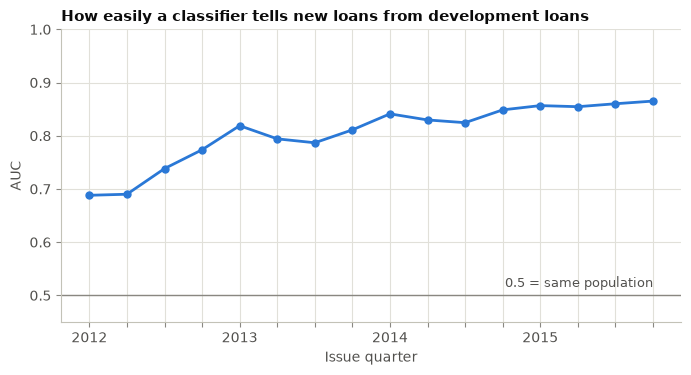

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(range(len(quarters)), old_new["auc"], color=MODEL_COLORS["pd_logit"], marker="o")
ax.axhline(0.5, color=INK_MUTED, linewidth=1)
ax.text(len(quarters) - 1, 0.51, "0.5 = same population", ha="right", va="bottom", color=INK_SOFT, fontsize=9)
ax.set_ylim(0.45, 1)
ax.set_xlabel("Issue quarter")
ax.set_ylabel("AUC")
ax.set_title("How easily a classifier tells new loans from development loans")
label_quarters(ax, quarters)
fig.savefig(FIGURES / "old_vs_new_auc.png")

**What section 1 says.** The borrowers changed quickly and a lot. Already in 2012Q1 a classifier separates the new loans from the development loans with an AUC of 0.69; the AUC is around 0.8 through 2013 and reaches 0.87 in 2015Q4. The new loans are larger (average amount from 9,600 to 12,800 dollars), go to borrowers with a lower FICO score (717 to 696) and a higher debt-to-income ratio (13 to 18), and are more often meant to refinance credit cards (14% to 25%) and less often to fund a small business (4% to 1%). From 2012Q3 FICO is the feature that most gives a new loan away in every quarter, and DTI is always among the first five.

## 2. A changed relationship

### 2.1 The logistic regression, re-estimated year by year

The same logistic regression is fitted again on the loans of each issue year. The features are always standardised with the development mean and standard deviation, so a coefficient means the same thing in every year and the lines can be compared.

A coefficient that moves can be noise. Each estimate therefore has a 95% bootstrap interval (100 resamples): a change is believed only when the intervals do not overlap. The dashed grey line is the coefficient of the frozen model.

In [6]:
preprocess = logit["preprocess"]
names = preprocess.get_feature_names_out()
frozen_coefficients = pd.Series(logit["model"].coef_[0], index=names)

yearly = []
for year, cohort in loans.groupby("issue_year"):
    coefficient, low, high = bootstrap_coefficients(logit["model"], preprocess.transform(cohort[FEATURES]), cohort["target"])
    yearly.append(pd.DataFrame({"issue_year": year, "feature": names, "coefficient": coefficient, "low": low, "high": high}))
yearly = pd.concat(yearly, ignore_index=True)
yearly.to_csv(FIGURES / "table_coefficients_by_year.csv", index=False)

yearly.pivot(index="feature", columns="issue_year", values="coefficient").loc[names].round(2)

issue_year,2009,2010,2011,2012,2013,2014,2015
feature,,,,,,,
loan_amnt,0.33,0.20,0.10,0.21,0.17,0.15,0.13
log_annual_inc,-0.33,-0.28,-0.38,-0.33,-0.34,-0.24,-0.17
dti,0.05,-0.02,0.02,0.06,0.13,0.12,0.15
fico,-0.26,-0.41,-0.38,-0.44,-0.41,-0.42,-0.41
emp_length_years,0.10,0.08,0.06,0.04,0.01,-0.01,0.03
log_revol_bal,-0.01,-0.16,-0.12,-0.27,-0.22,-0.22,-0.32
revol_util,0.13,0.24,0.25,0.13,0.09,0.14,0.08
open_acc,0.05,0.04,0.06,0.11,0.15,0.14,0.12
total_acc,-0.03,-0.02,-0.02,-0.07,-0.15,-0.12,-0.07


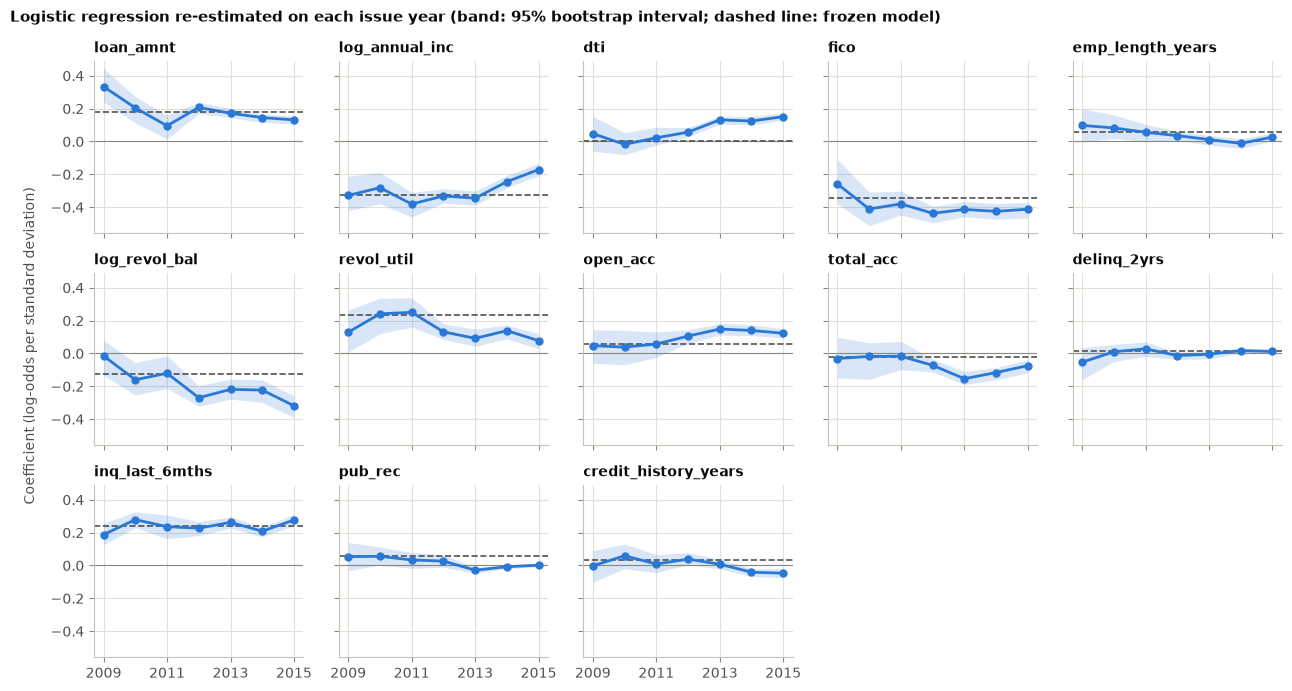

In [7]:
fig, axes = plt.subplots(3, 5, figsize=(13, 7), sharex=True, sharey=True)
for ax, feature in zip(axes.flat, NUMERIC_FEATURES):
    data = yearly[yearly["feature"] == feature]
    ax.axhline(0, color=INK_MUTED, linewidth=0.8)
    ax.axhline(frozen_coefficients[feature], color=INK_SOFT, linewidth=1.2, linestyle="--")
    ax.fill_between(data["issue_year"], data["low"], data["high"], color=MODEL_COLORS["pd_logit"], alpha=0.18, linewidth=0)
    ax.plot(data["issue_year"], data["coefficient"], color=MODEL_COLORS["pd_logit"], marker="o")
    ax.set_title(feature, fontsize=10)
    ax.set_xticks([2009, 2011, 2013, 2015])
for ax in axes.flat[len(NUMERIC_FEATURES):]:
    ax.set_visible(False)
fig.supylabel("Coefficient (log-odds per standard deviation)", color=INK_SOFT, fontsize=10)
fig.suptitle("Logistic regression re-estimated on each issue year (band: 95% bootstrap interval; dashed line: frozen model)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "coefficients_over_time.png")

**Which coefficients really changed?** The estimate on all the development loans is compared with the estimate on the 2015 loans, for the numeric features. A coefficient counts as changed only when the two 95% intervals do not overlap.

In [8]:
coefficient, low, high = bootstrap_coefficients(logit["model"], preprocess.transform(development[FEATURES]),
                                                development["target"])
at_development = pd.DataFrame({"development": coefficient, "development_low": low, "development_high": high}, index=names)
in_2015 = yearly[yearly["issue_year"] == 2015].set_index("feature")[["coefficient", "low", "high"]]
in_2015.columns = ["estimated_2015", "low_2015", "high_2015"]

changed = at_development.join(in_2015).loc[NUMERIC_FEATURES]
changed["changed"] = (changed["development_high"] < changed["low_2015"]) | (changed["development_low"] > changed["high_2015"])
changed.to_csv(FIGURES / "table_coefficients_changed.csv", index_label="feature")
changed.round(3)

,development,development_low,development_high,estimated_2015,low_2015,high_2015,changed
loan_amnt,0.171,0.114,0.219,0.132,0.107,0.155,False
log_annual_inc,-0.328,-0.374,-0.274,-0.171,-0.209,-0.133,True
dti,0.015,-0.029,0.054,0.151,0.130,0.174,True
fico,-0.359,-0.397,-0.301,-0.412,-0.467,-0.370,False
emp_length_years,0.071,0.035,0.115,0.027,0.003,0.052,False
log_revol_bal,-0.106,-0.159,-0.055,-0.318,-0.390,-0.257,True
revol_util,0.222,0.183,0.272,0.078,0.029,0.120,True
open_acc,0.052,-0.019,0.094,0.123,0.096,0.150,True
total_acc,-0.019,-0.085,0.047,-0.074,-0.118,-0.037,False
delinq_2yrs,0.012,-0.030,0.048,0.012,0.003,0.026,False


### 2.2 XGBoost: permutation importance by year

XGBoost has no coefficients, so the question is asked differently: how much does the frozen model lose when one feature is shuffled? The loss in AUC is the importance of that feature for ranking the loans of that period. A feature whose importance fades is a feature that no longer separates good and bad borrowers as it did at development. The first column is the development holdout, the others are the monitoring years.

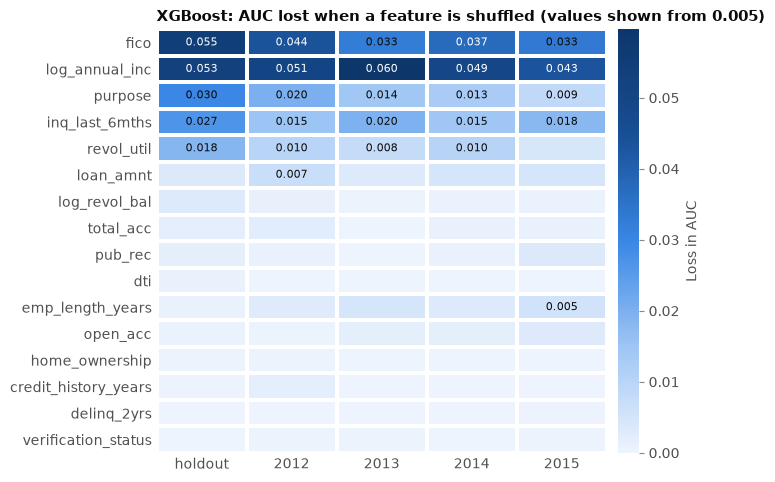

In [9]:
holdout = loans[loans["sample"] == "holdout"]
importance = {}
for period in PERIODS:
    cohort = holdout if period == "development" else loans[loans["period"] == period]
    result = permutation_importance(xgb, cohort[FEATURES], cohort["target"], scoring="roc_auc",
                                    n_repeats=3, random_state=SEED)
    importance[period] = pd.Series(result.importances_mean, index=FEATURES)
importance = pd.DataFrame(importance).rename(columns={"development": "holdout"})
importance = importance.sort_values("holdout", ascending=False)
importance.to_csv(FIGURES / "table_permutation_importance.csv", index_label="feature")

fig, ax = plt.subplots(figsize=(7, 5.5))
mesh = ax.pcolormesh(importance, cmap=BLUES, vmin=0, vmax=importance.to_numpy().max(), edgecolors="white", linewidth=1.5)
# Only the cells worth at least half a point of AUC are labelled.
for row, feature in enumerate(importance.index):
    for column, value in enumerate(importance.loc[feature]):
        if value >= 0.005:
            ax.text(column + 0.5, row + 0.5, f"{value:.3f}", ha="center", va="center", fontsize=8,
                    color="white" if value > 0.6 * importance.to_numpy().max() else INK)
ax.invert_yaxis()
ax.set_xticks(np.arange(importance.shape[1]) + 0.5, importance.columns)
ax.set_yticks(np.arange(len(importance)) + 0.5, importance.index)
ax.set_title("XGBoost: AUC lost when a feature is shuffled (values shown from 0.005)")
ax.grid(False)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
colorbar = fig.colorbar(mesh, ax=ax, pad=0.02)
colorbar.set_label("Loss in AUC")
colorbar.outline.set_visible(False)
fig.savefig(FIGURES / "permutation_importance.png")

**What section 2 says.** The relationship changed too, but only for some features. Between development and 2015 six of the thirteen numeric coefficients moved beyond their intervals. Income lost about half of its weight (-0.33 to -0.17) and revolving utilisation two thirds (0.22 to 0.08); DTI, which was close to zero at development, became a risk driver (0.15), and the revolving balance became more protective (-0.11 to -0.32). FICO and recent inquiries kept their weight. XGBoost tells the same story from another angle: shuffling FICO costs 0.055 of AUC on the holdout but 0.033 in 2015, and the loss from the loan purpose falls from 0.030 to 0.009.

## 3. Occupation

The question raised on the proposal: do teachers repay differently from other borrowers, and is the difference stable?

`emp_title` holds a job title only for the loans issued from October 2013 (flag `title_is_job`, built in stage 2), so this section uses the nine cohorts from 2013Q4 to 2015Q4. Occupation is studied on its own and is not a feature of the models, because it did not exist in the development years.

### 3.1 Default rate by occupation

The interval is the Wilson interval for a proportion, which behaves well also for small groups. Groups with fewer than 300 loans in a period are flagged: their rate is too unstable to draw conclusions.

In [10]:
def wilson_interval(defaults, loans_count, z=1.96):
    # Wilson score interval (Wilson, 1927).
    rate = defaults / loans_count
    centre = (rate + z**2 / (2 * loans_count)) / (1 + z**2 / loans_count)
    half_width = z * np.sqrt(rate * (1 - rate) / loans_count + z**2 / (4 * loans_count**2)) / (1 + z**2 / loans_count)
    return centre - half_width, centre + half_width


def default_table(data, by):
    table = data.groupby(by)["target"].agg(loans="size", defaults="sum")
    table["default_rate"] = table["defaults"] / table["loans"]
    table["low"], table["high"] = wilson_interval(table["defaults"], table["loans"])
    table["small_group"] = table["loans"] < 300
    return table


jobs = loans[loans["title_is_job"]].copy()
jobs["period"] = np.where(jobs["issue_year"] == 2013, "2013Q4", jobs["issue_year"].astype(str))
JOB_PERIODS = ["2013Q4", "2014", "2015"]

by_occupation = default_table(jobs, "occupation_group").sort_values("default_rate")
by_occupation_period = default_table(jobs, ["occupation_group", "period"])
by_occupation_period.to_csv(FIGURES / "table_occupation_by_period.csv")
by_occupation.to_csv(FIGURES / "table_occupation.csv")

print(f"{len(jobs):,} loans with a job title, overall default rate {jobs['target'].mean():.3f}")
by_occupation.round(3)

108,000 loans with a job title, overall default rate 0.139


,loans,defaults,default_rate,low,high,small_group
occupation_group,,,,,,
engineer,3243,277,0.085,0.076,0.096,False
analyst,2865,264,0.092,0.082,0.103,False
executive,2084,202,0.097,0.085,0.110,False
director,3937,383,0.097,0.088,0.107,False
consultant,1043,114,0.109,0.092,0.130,False
officer,2267,256,0.113,0.101,0.127,False
nurse,3889,455,0.117,0.107,0.127,False
teacher,3238,397,0.123,0.112,0.134,False
specialist,2699,342,0.127,0.115,0.140,False


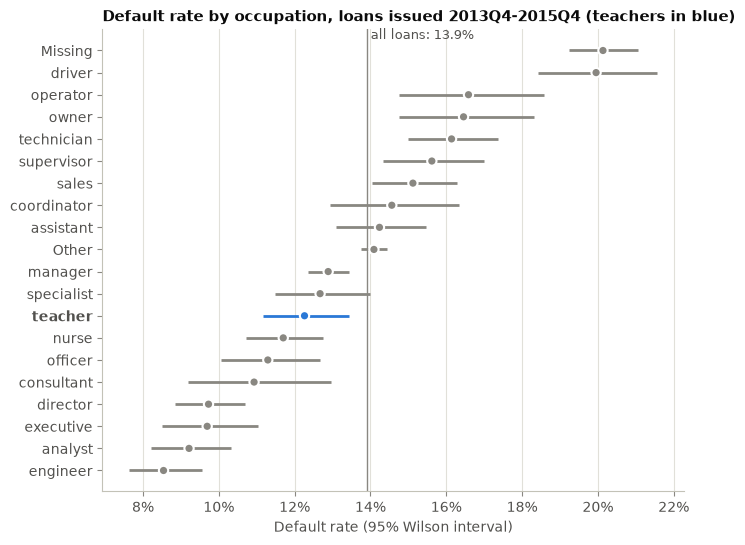

In [11]:
overall_rate = jobs["target"].mean()
positions = np.arange(len(by_occupation))
is_teacher = by_occupation.index == "teacher"
colours = np.where(is_teacher, MODEL_COLORS["pd_logit"], INK_MUTED)

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.axvline(overall_rate, color=INK_MUTED, linewidth=1)
ax.text(overall_rate, len(by_occupation) - 0.3, f" all loans: {overall_rate:.1%}", color=INK_SOFT, fontsize=9, va="center")
ax.hlines(positions, by_occupation["low"], by_occupation["high"], colors=colours, linewidth=2)
ax.scatter(by_occupation["default_rate"], positions, c=colours, s=45, zorder=3, edgecolors="white", linewidths=1.5)
ax.set_yticks(positions, by_occupation.index)
ax.get_yticklabels()[int(np.argmax(is_teacher))].set_fontweight("bold")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
ax.set_xlabel("Default rate (95% Wilson interval)")
ax.set_title("Default rate by occupation, loans issued 2013Q4-2015Q4 (teachers in blue)")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "occupation_default_rates.png")

**Is the difference stable?** The default rate of teachers next to the rate of all the loans with a job title, period by period.

In [12]:
teachers = by_occupation_period.loc["teacher"].loc[JOB_PERIODS, ["loans", "default_rate", "low", "high", "small_group"]]
teachers["all_loans_default_rate"] = jobs.groupby("period")["target"].mean()
teachers.round(3)

,loans,default_rate,low,high,small_group,all_loans_default_rate
period,,,,,,
2013Q4,359,0.109,0.080,0.145,False,0.116
2014,1446,0.127,0.111,0.145,False,0.135
2015,1433,0.121,0.106,0.139,False,0.149


### 3.2 Occupation next to the other features

Teachers could repay better simply because they have, say, better FICO scores. A logistic regression with the model features **and** the occupation group answers this: the coefficient of an occupation is its effect once income, FICO, DTI and the rest are already taken into account. It is shown as an odds ratio against the group `Other` (1 = no difference, below 1 = safer), with a 95% bootstrap interval.

In [13]:
occupation_encoder = OneHotEncoder(drop=["Other"], sparse_output=False).fit(jobs[["occupation_group"]])
occupation_names = [name.replace("occupation_group_", "") for name in occupation_encoder.get_feature_names_out()]


def occupation_odds_ratios(data):
    X = np.hstack([preprocess.transform(data[FEATURES]), occupation_encoder.transform(data[["occupation_group"]])])
    coefficient, low, high = bootstrap_coefficients(logit["model"], X, data["target"])
    # The occupation columns are the last ones of the design matrix.
    table = pd.DataFrame({"odds_ratio": coefficient, "low": low, "high": high}).iloc[-len(occupation_names):]
    table.index = occupation_names
    return np.exp(table)


odds_ratios = occupation_odds_ratios(jobs).sort_values("odds_ratio")
odds_ratios["different_from_other"] = (odds_ratios["high"] < 1) | (odds_ratios["low"] > 1)
odds_ratios.to_csv(FIGURES / "table_occupation_odds_ratios.csv", index_label="occupation_group")
odds_ratios.round(3)

,odds_ratio,low,high,different_from_other
analyst,0.692,0.596,0.794,True
engineer,0.736,0.651,0.825,True
nurse,0.846,0.783,0.946,True
director,0.848,0.759,0.953,True
officer,0.863,0.753,0.968,True
teacher,0.880,0.789,0.971,True
specialist,0.888,0.768,0.984,True
consultant,0.896,0.764,1.107,False
assistant,0.949,0.865,1.039,False
executive,0.955,0.790,1.087,False


The same model fitted separately on each period, reading only the teachers' odds ratio.

In [14]:
teacher_by_period = pd.DataFrame({
    period: occupation_odds_ratios(jobs[jobs["period"] == period]).loc["teacher"] for period in JOB_PERIODS
}).T
teacher_by_period.to_csv(FIGURES / "table_teacher_odds_ratio_by_period.csv", index_label="period")
teacher_by_period.round(3)

,odds_ratio,low,high
2013Q4,0.933,0.666,1.284
2014,0.958,0.825,1.090
2015,0.804,0.619,0.945


**What section 3 says.** Teachers repay slightly better than the average borrower: 12.3% of them default (95% interval 11.2-13.4%) against 13.9% of all the loans with a job title. Their other characteristics explain part of it: once the model features are taken into account the odds ratio against `Other` is 0.88 (0.79-0.97). The difference is not stable enough to rely on: in the single periods the odds ratio is 0.93, 0.96 and 0.80, and only in 2015 is the interval entirely below 1.

Occupation as a whole carries information that the models do not have. With the same features, engineers and analysts are much safer than `Other` (odds ratios 0.74 and 0.69), drivers and business owners much riskier (1.47 and 1.34), and an empty job title is itself a warning sign (20.1% default).

## 4. Only a shifted level, or more?

For each quarter three versions of every model are compared:

- **frozen**: the model built on 2009-2011, as it is;
- **recalibrated**: the frozen model with one number changed, the intercept, so that the mean PD equals the observed default rate of the quarter. The ranking of the loans stays the same, so the Gini cannot change;
- **re-estimated**: the same recipe fitted again on the loans of the quarter. Its predictions are cross-validated, so every loan is scored by a model that has not seen it.

If the recalibrated model is as good as the re-estimated one, only the level moved and a simple recalibration is enough. If the re-estimated model ranks better, the relationship between features and default has changed and the model must be rebuilt. The log-loss measures the quality of the probabilities (lower is better).

The comparison is conservative: the re-estimated model learns from one quarter only (at most 9,600 loans in each fold), fewer than the 22,830 loans behind the frozen model.

In [15]:
def shift_intercept(prob, target):
    # The constant added to the log-odds that makes the mean PD equal to the observed default rate.
    log_odds = to_log_odds(prob)
    shift = brentq(lambda constant: expit(log_odds + constant).mean() - target.mean(), -5, 5)
    return expit(log_odds + shift)


RECIPES = {"pd_logit": make_logit, "pd_xgb": lambda: make_xgb(xgb["model"].n_estimators)}

versions = []
for quarter in quarters:
    cohort = monitoring[monitoring["issue_quarter"] == quarter]
    target = cohort["target"]
    for model, recipe in RECIPES.items():
        predictions = {
            "frozen": cohort[model],
            "recalibrated": shift_intercept(cohort[model], target),
            "re-estimated": cross_val_predict(recipe(), cohort[FEATURES], target, cv=folds, method="predict_proba")[:, 1],
        }
        for version, prob in predictions.items():
            versions.append({
                "issue_quarter": quarter, "model": model, "version": version,
                "gini": gini(target, prob),
                "calibration_gap": target.mean() / prob.mean() - 1,
                "log_loss": log_loss(target, prob),
            })
versions = pd.DataFrame(versions)
versions.to_csv(FIGURES / "table_frozen_recalibrated_reestimated.csv", index=False)

print("Last quarter (2015Q4):")
versions[versions["issue_quarter"] == quarters[-1]].set_index(["model", "version"])[["gini", "calibration_gap", "log_loss"]].round(4)

Last quarter (2015Q4):


gini  calibration_gap  log_loss
model    version                                        
pd_logit frozen        0.2902           0.2025    0.4106
         recalibrated  0.2902           0.0000    0.4077
         re-estimated  0.3336          -0.0007    0.4018
pd_xgb   frozen        0.2757           0.2177    0.4117
         recalibrated  0.2757          -0.0000    0.4085
         re-estimated  0.3263          -0.0009    0.4022

The same comparison for every quarter. The distance between the two lines is what is lost by keeping the old model instead of rebuilding it: the cost of the changed relationship.

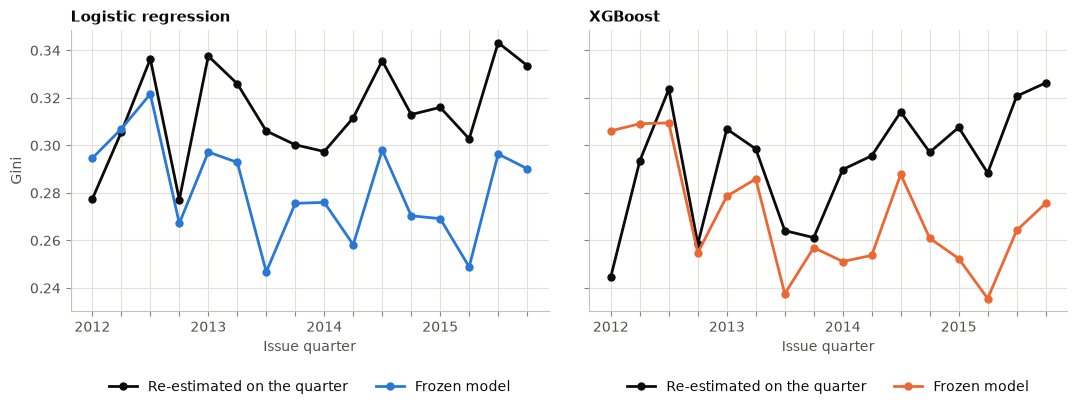

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for ax, model in zip(axes, RECIPES):
    data = versions[versions["model"] == model].pivot(index="issue_quarter", columns="version", values="gini")
    x = range(len(data))
    ax.plot(x, data["re-estimated"], color=INK, marker="o", label="Re-estimated on the quarter")
    ax.plot(x, data["frozen"], color=MODEL_COLORS[model], marker="o", label="Frozen model")
    ax.set_title(MODEL_LABELS[model])
    ax.set_xlabel("Issue quarter")
    label_quarters(ax, quarters)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
axes[0].set_ylabel("Gini")
fig.tight_layout()
fig.savefig(FIGURES / "frozen_vs_reestimated.png")

Averages by issue year. `gini_gap` is the Gini of the re-estimated model minus the Gini of the frozen one. The last two columns are the improvement in log-loss over the frozen model: from the intercept alone, and from re-estimating.

In [17]:
wide = versions.pivot(index=["model", "issue_quarter"], columns="version", values=["gini", "log_loss"])
by_year = pd.DataFrame({
    "gini_frozen": wide[("gini", "frozen")],
    "gini_reestimated": wide[("gini", "re-estimated")],
    "log_loss_frozen": wide[("log_loss", "frozen")],
    "log_loss_recalibrated": wide[("log_loss", "recalibrated")],
    "log_loss_reestimated": wide[("log_loss", "re-estimated")],
}).reset_index()
by_year["issue_year"] = by_year["issue_quarter"].str[:4]
by_year = by_year.groupby(["model", "issue_year"]).mean(numeric_only=True)
by_year["gini_gap"] = by_year["gini_reestimated"] - by_year["gini_frozen"]
by_year["log_loss_gain_recalibrated"] = by_year["log_loss_frozen"] - by_year["log_loss_recalibrated"]
by_year["log_loss_gain_reestimated"] = by_year["log_loss_frozen"] - by_year["log_loss_reestimated"]
by_year.to_csv(FIGURES / "table_reestimation_by_year.csv")
by_year[["gini_frozen", "gini_reestimated", "gini_gap", "log_loss_gain_recalibrated", "log_loss_gain_reestimated"]].round(4)

gini_frozen  gini_reestimated  gini_gap  \
model    issue_year                                            
pd_logit 2012             0.2976            0.2992    0.0016   
         2013             0.2781            0.3175    0.0394   
         2014             0.2757            0.3144    0.0387   
         2015             0.2762            0.3239    0.0477   
pd_xgb   2012             0.2949            0.2801   -0.0147   
         2013             0.2648            0.2827    0.0179   
         2014             0.2634            0.2992    0.0358   
         2015             0.2570            0.3108    0.0538   

                     log_loss_gain_recalibrated  log_loss_gain_reestimated  
model    issue_year                                                         
pd_logit 2012                            0.0012                     0.0017  
         2013                            0.0003                     0.0050  
         2014                            0.0004                     0.0058  
         2015                            0.0021                     0.0083  
pd_xgb   2012                            0.0017                     0.0001  
         2013                            0.0001                     0.0020  
         2014                            0.0004                     0.0048  
         2015                            0.0024                     0.0090

**What section 4 says.** A shifted level is only part of the problem. Recalibrating the intercept removes the calibration gap by construction, but it cannot change the Gini. In 2012 there is nothing more to gain: a logistic regression rebuilt on the same quarter ranks no better than the frozen one (0.299 against 0.298). From 2013 the rebuilt model is ahead by about 0.04 Gini and by 0.05 in 2015 (0.324 against 0.276); for XGBoost the distance grows from 0.02 in 2013 to 0.05 in 2015. The relationship between features and default drifts away gradually, and this part of the decay needs a new model, not a recalibration.

The rebuilt models also show how much of the first drop could never be recovered. Even when fitted on the monitoring loans themselves, the logistic regression reaches a Gini of 0.30-0.32, well below the 0.39 of development: the later population is harder to rank with these features.

## 5. PCA: the drift of all the features together

The PSI looks at one feature at a time. PCA summarises the thirteen numeric features in a few directions (components) that capture most of their joint variation. The scaler and the PCA are fitted on the development sample only; later cohorts are projected on the same directions. Two things are measured for each quarter:

- **the shift of the centre**: the average position of the cohort on the first two components, in development standard deviations (0 = where the development sample is);
- **the reconstruction error**: how badly five components rebuild the loans of the cohort, relative to the development sample (1 = as well as at development). It rises when the features combine in ways that did not exist at development. The median is used because a few extreme loans would dominate the mean.

In [18]:
N_COMPONENTS = 5
prepare = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(development[NUMERIC_FEATURES])
pca = PCA(n_components=N_COMPONENTS).fit(prepare.transform(development[NUMERIC_FEATURES]))
print("Variance explained by each component:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

loadings = pd.DataFrame(pca.components_.T, index=NUMERIC_FEATURES,
                        columns=[f"PC{i + 1}" for i in range(N_COMPONENTS)])
loadings.to_csv(FIGURES / "table_pca_loadings.csv", index_label="feature")
loadings.round(2)

Variance explained by each component: [0.213 0.154 0.099 0.091 0.081] | total: 0.638


,PC1,PC2,PC3,PC4,PC5
loan_amnt,0.31,-0.08,-0.37,0.02,-0.35
log_annual_inc,0.39,-0.12,-0.22,0.23,-0.35
dti,0.19,0.35,0.21,-0.35,0.34
fico,0.05,-0.57,-0.18,-0.23,0.18
emp_length_years,0.23,-0.09,-0.10,0.38,0.42
log_revol_bal,0.35,0.34,-0.27,-0.11,-0.01
revol_util,0.07,0.59,-0.29,0.11,-0.01
open_acc,0.43,0.01,0.37,-0.25,-0.00
total_acc,0.48,-0.09,0.29,-0.11,0.01
delinq_2yrs,0.01,0.04,0.36,0.48,-0.30


In [19]:
def pca_position(data):
    standardised = prepare.transform(data[NUMERIC_FEATURES])
    components = pca.transform(standardised)
    error = ((standardised - pca.inverse_transform(components)) ** 2).sum(axis=1)
    # Dividing by the development standard deviation of each component puts the shift in comparable units.
    return components / np.sqrt(pca.explained_variance_), error


_, development_error = pca_position(development)
pca_drift = []
for quarter in quarters:
    position, error = pca_position(monitoring[monitoring["issue_quarter"] == quarter])
    pca_drift.append({
        "issue_quarter": quarter,
        "shift_pc1": position[:, 0].mean(),
        "shift_pc2": position[:, 1].mean(),
        "reconstruction_error": np.median(error) / np.median(development_error),
    })
pca_drift = pd.DataFrame(pca_drift).set_index("issue_quarter")
pca_drift.to_csv(FIGURES / "table_pca_drift.csv")
pca_drift.round(3)

,shift_pc1,shift_pc2,reconstruction_error
issue_quarter,,,
2012Q1,0.204,0.233,0.924
2012Q2,0.236,0.327,0.995
2012Q3,0.328,0.452,1.036
2012Q4,0.486,0.495,1.139
2013Q1,0.616,0.573,1.196
2013Q2,0.479,0.510,1.224
2013Q3,0.458,0.486,1.260
2013Q4,0.587,0.466,1.328
2014Q1,0.629,0.505,1.548


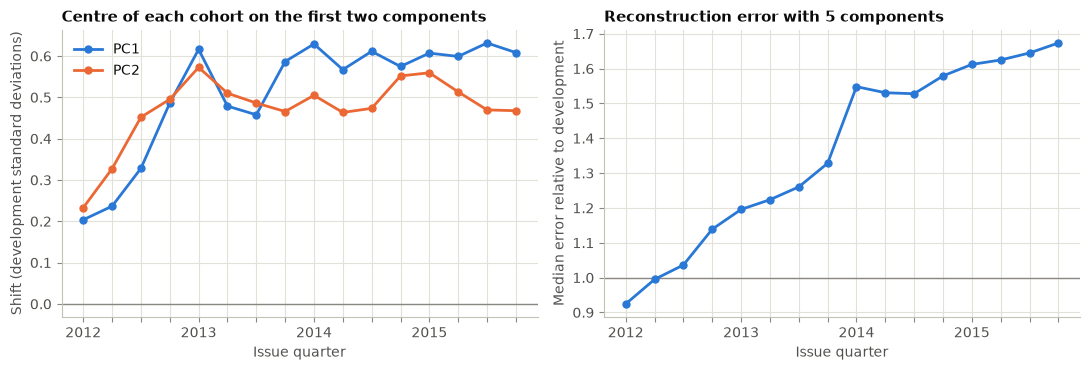

In [20]:
x = range(len(quarters))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].axhline(0, color=INK_MUTED, linewidth=1)
axes[0].plot(x, pca_drift["shift_pc1"], color=MODEL_COLORS["pd_logit"], marker="o", label="PC1")
axes[0].plot(x, pca_drift["shift_pc2"], color=MODEL_COLORS["pd_xgb"], marker="o", label="PC2")
axes[0].set_ylabel("Shift (development standard deviations)")
axes[0].set_title("Centre of each cohort on the first two components")
axes[0].legend()

axes[1].axhline(1, color=INK_MUTED, linewidth=1)
axes[1].plot(x, pca_drift["reconstruction_error"], color=MODEL_COLORS["pd_logit"], marker="o")
axes[1].set_ylabel("Median error relative to development")
axes[1].set_title(f"Reconstruction error with {N_COMPONENTS} components")

for ax in axes:
    ax.set_xlabel("Issue quarter")
    label_quarters(ax, quarters)
fig.tight_layout()
fig.savefig(FIGURES / "pca_drift.png")

**What section 5 says.** Five components explain 64% of the variance of the numeric features. The first (21%) is the size of the borrower's credit file: number of accounts, income, revolving balance, length of the credit history, loan amount. The second (15%) is credit stress: high revolving utilisation and DTI, low FICO. The later cohorts sit about 0.6 development standard deviations higher on the first component and 0.5 on the second: larger credit files and more stretched borrowers. This move is complete by early 2013 and then stays. The reconstruction error keeps growing instead, from about the development level in early 2012 to 1.67 times in 2015Q4, with a jump at the start of 2014: the features increasingly combine in ways that the development sample did not contain.

## 6. Summary: why the models degrade

| Cause | Evidence | Remedy |
| --- | --- | --- |
| Different borrowers | Old-versus-new AUC from 0.69 to 0.87; purpose, FICO and DTI red on the PSI; a model rebuilt on the new loans reaches a Gini of only 0.30-0.32 | None for the ranking power: the new population is harder to separate |
| A changed relationship | Six of thirteen coefficients moved beyond their intervals; from 2013 the frozen models lose 0.02-0.05 Gini against rebuilt ones | Re-estimate the model |
| A shifted level | Mean PD 12-22% too low in early 2012 and 10-22% too low in 2015 | Recalibrate the intercept |

The loss of discrimination seen in stage 4 is mostly the first cause in 2012 and a mix of the first and the second from 2013. The calibration problem of 2015 is the third.